# Login timing side channel (2.8)

*Login timing side channel*. When you log in, the server looks up the
username and checks the password with argon2. A real account runs that argon2 hash. A
username that does not exist can skip the hash and answer sooner, and that time
difference tells an attacker which usernames are real. Real usernames are a head start
for password brute forcing or phishing.

The defence is `LOGIN_TIMING_DEFENCE`. With it on, an unknown username still runs one
argon2 verify against a fixed dummy hash, so both replies take about the same time.

Required is the response times of real and unknown usernames, before and after the
defence, so that is what this notebook produces. It runs the whole experiment itself, self-encapsulated:

1. start the API on a spare port (8001) with the defence off, time the logins, stop it;
2. start it again with the defence on, time the same logins, stop it;
3. save the raw timings, print the median gap, and plot the before and after.


Use *Run All*. Docker has to be available for Postgres
We bring the database up and seed the `admin` account.

In [1]:
import json
import os
import subprocess
import sys
import tempfile
import time
import urllib.error
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Run from model-backend/ no matter where the kernel started.
HERE = Path.cwd()
BACKEND = HERE if (HERE / "app" / "main.py").is_file() else HERE.parent
assert (BACKEND / "app" / "main.py").is_file(), f"open this from model-backend/, got {BACKEND}"
OUT = BACKEND / "security_eval"
OUT.mkdir(exist_ok=True)

PYTHON = sys.executable          # the venv running this kernel
PORT = 8001                      # spare port; never the dev server on 8000
BASE = f"http://127.0.0.1:{PORT}"

KNOWN = "admin"                              # seeded below, so it exists
UNKNOWN = "invalid_username"                 # a username that does not exist
WRONG_PW = "definitely-wrong-password-123"   # not a correct password

WARMUP = 5      # discard the first few replies per series (cold database cache)
SAMPLES = 100   # timed replies per username per condition

# Why 100: argon2id verify costs tens of ms, far above localhost network noise, so the
# known/unknown gap is easy to see
print(f"backend: {BACKEND}")
print(f"will attack: {BASE}")

backend: F:\University\Year 2\S2\Computing Technology Innovation Project\Assignment 3\model-backend
will attack: http://127.0.0.1:8001


## 1. Bring up Postgres and seed the `admin` account

Safe to re-run. It does nothing if the database is already up, and only creates `admin`
when that account is missing.

In [2]:
subprocess.run(["docker", "compose", "up", "-d"], cwd=BACKEND, check=True)

# docker reports the container up before Postgres accepts connections, so retry the seed
for attempt in range(10):
    done = subprocess.run([PYTHON, "-m", "scripts.seed"], cwd=BACKEND)
    if done.returncode == 0:
        break
    time.sleep(1.5)
else:
    raise RuntimeError("seed never succeeded - is Docker running?")

## 2. Server control and the timing probe

In [3]:
def wait_health(timeout=45):
    deadline = time.time() + timeout
    while time.time() < deadline:
        try:
            with urllib.request.urlopen(BASE + "/api/health", timeout=2) as r:
                if r.status == 200:
                    return True
        except (urllib.error.URLError, ConnectionError):
            time.sleep(0.3)
    return False


def start_server(defence: bool):
    """Launch uvicorn on PORT with the timing defence on/off. Returns the process."""
    env = {
        **os.environ,
        "LOGIN_TIMING_DEFENCE": "true" if defence else "false",
        "RATE_LIMIT_ENABLED": "false",   # no 429s to pollute the timing
        "LOGIN_RATE_LIMIT": "100000",
    }
    
    
    log = tempfile.NamedTemporaryFile("w+", suffix="-uvicorn.log", delete=False)
    proc = subprocess.Popen(
        [PYTHON, "-m", "uvicorn", "app.main:app", "--host", "127.0.0.1", "--port", str(PORT), "--log-level", "warning"],
        cwd=BACKEND, env=env, stdout=log, stderr=subprocess.STDOUT,
    )
    if not wait_health():
        proc.terminate()
        tail = Path(log.name).read_text()[-20:]
        raise RuntimeError(f"server did not come up on port {PORT}\n--- server log ---\n{tail}")
    print(f"server up on port {PORT}  (LOGIN_TIMING_DEFENCE={'on' if defence else 'off'})")
    return proc


def stop_server(proc):
    proc.terminate()
    try:
        proc.wait(timeout=10)
    except subprocess.TimeoutExpired:
        proc.kill()


def login_latency(username: str) -> float:
    """Seconds for one POST /api/login. A 401 is expected and still timed"""
    body = json.dumps({"username": username, "password": WRONG_PW}).encode()
    req = urllib.request.Request(
        BASE + "/api/login", data=body,
        headers={"Content-Type": "application/json"}, method="POST",
    )
    start = time.perf_counter()
    try:
        urllib.request.urlopen(req, timeout=10).read()
    except urllib.error.HTTPError as e:   # 401 wrong username/password
        e.read()
    return time.perf_counter() - start


def measure(username: str) -> list[float]:
    for _ in range(WARMUP):
        login_latency(username)
    return [login_latency(username) * 1000 for _ in range(SAMPLES)]   # milliseconds

## 3. Measure: defence off, then defence on

Each condition starts a fresh server and stops it in a `finally`, so nothing is left
running on :8001.

In [4]:
proc = start_server(defence=False)
try:
    off_known   = measure(KNOWN)
    off_unknown = measure(UNKNOWN)
finally:
    stop_server(proc)

proc = start_server(defence=True)
try:
    on_known   = measure(KNOWN)
    on_unknown = measure(UNKNOWN)
finally:
    stop_server(proc)

print("done measuring")

server up on port 8001  (LOGIN_TIMING_DEFENCE=off)


server up on port 8001  (LOGIN_TIMING_DEFENCE=on)


done measuring


## 4. Save the raw timings and read the gap

In [5]:
rows = []
for cond, known, unknown in [("off", off_known, off_unknown), ("on", on_known, on_unknown)]:
    rows += [{"defence": cond, "username": "known",   "ms": v} for v in known]
    rows += [{"defence": cond, "username": "unknown", "ms": v} for v in unknown]
df = pd.DataFrame(rows)
df.to_csv(OUT / "login_timing_raw.csv", index=False)

summary = df.groupby(["defence", "username"])["ms"].median().unstack()
summary["gap_ms"] = summary["known"] - summary["unknown"]
summary = summary.reindex(["off", "on"])
print(summary.round(1))

GAP_MS = 4   # localhost noise - true gap is more than just localhost noise (4 is probably safe default, localhost is <1 usually)
print()
for cond in ["off", "on"]:
    gap = summary.loc[cond, "gap_ms"]
    leaks = gap > GAP_MS
    tag = "ATTACK SUCCEEDED - usernames leak" if leaks else "ATTACK BLOCKED - times match"
    print(f"[{tag}]  defence {cond}: known - unknown median gap = {gap:+.1f} ms")

username  known  unknown  gap_ms
defence                         
off        55.7      8.7    47.0
on         53.4     53.8    -0.3

[ATTACK SUCCEEDED - usernames leak]  defence off: known - unknown median gap = +47.0 ms
[ATTACK BLOCKED - times match]  defence on: known - unknown median gap = -0.3 ms


## 5. Plot the before and after

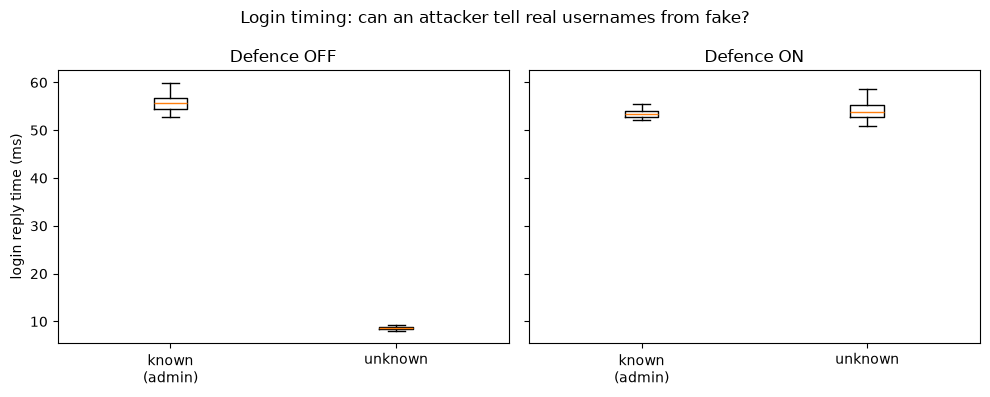

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, cond, title in [(axes[0], "off", "Defence OFF"),
                        (axes[1], "on", "Defence ON")]:
    sub = df[df.defence == cond]
    ax.boxplot([sub[sub.username == "known"].ms, sub[sub.username == "unknown"].ms], showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(["known\n(admin)", "unknown"])
    ax.set_title(title)


axes[0].set_ylabel("login reply time (ms)")
fig.suptitle("Login timing: can an attacker tell real usernames from fake?")
fig.tight_layout()
fig.savefig(OUT / "login_timing.png", dpi=300)
plt.show()

## 6. What the numbers say

With the defence off, a known username is slower than an unknown one by about one argon2
verify. The gap is far larger than localhost noise, so an attacker who times the replies
can sort real usernames from fake ones. With the defence on, the gap drops to noise,
because an unknown username now runs one argon2 verify against a fixed dummy hash as well.

What the defence does not fix:

- `POST /api/register` still answers 409 when a username is taken. That is a separate way
  to enumerate usernames, and this defence does not touch it
- A patient attacker can average many more samples and pull a smaller signal out of the
  jitter from other side channels like garbage collection or memory timings. 
  `LOGIN_RATE_LIMIT`, a separate defence, which caps how many samples they can get, 
  and over a real network the jitter helps the defender too.

Cost: one extra argon2 verify on each failed login for an unknown username, which is tens
of milliseconds of CPU and a short-lived ~64 MB of memory. The normal correct-login path
pays nothing extra therefore a user would not notice the difference.